In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, BaggingClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score

# Load data
df = pd.read_csv("/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New/DS1_aqi_corrected_cleaned.csv")

# Encode labels
label_enc = LabelEncoder()
df['AQI_Label'] = label_enc.fit_transform(df['AQI_Category'])

# Define features and target
features = ['SO2', 'NO2', 'CO', 'O3', 'PM2.5', 'PM10']
X = df[features]
y = df['AQI_Label']


In [3]:
# ============================================================
# STEP 1: Train-Test Split (Before Normalization)
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# ============================================================
# STEP 2: Normalize Features (Avoid Data Leakage)
# ============================================================

scaler = StandardScaler()

# Fit scaler only on training data
X_train = scaler.fit_transform(X_train)

# Transform test data using training scaler
X_test = scaler.transform(X_test)

# ============================================================
# STEP 3: Define Individual Models
# ============================================================

xgb_model = XGBClassifier(
    use_label_encoder=False,
        eval_metric='mlogloss',
        random_state=42,
)

bagging_model = BaggingClassifier(
    max_samples=0.8,
        max_features=0.8,
        random_state=42,
)

rf_model = RandomForestClassifier(
    max_depth=6,
        max_features=0.8,
        random_state=42,)

# svm_model = SVC(
#     probability=True,
#     random_state=42
# )

# ============================================================
# STEP 4: Create Voting Ensemble
# ============================================================

voting_clf = VotingClassifier(
    estimators=[
        ('xgb', xgb_model),
        ('bagging', bagging_model),
        ('rf', rf_model),
        # ('svm', svm_model)
    ],
    voting='soft'
)

# ============================================================
# STEP 5: Train Ensemble
# ============================================================

voting_clf.fit(X_train, y_train)

# ============================================================
# STEP 6: Predict
# ============================================================

y_pred = voting_clf.predict(X_test)

# ============================================================
# STEP 7: Evaluation
# ============================================================

print("=== Voting Ensemble Classification Report ===")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=label_enc.classes_,
        digits=4,
        zero_division=0
    )
)

print("Accuracy:", accuracy_score(y_test, y_pred))

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [17:39:00] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


=== Voting Ensemble Classification Report ===
              precision    recall  f1-score   support

        Good     1.0000    1.0000    1.0000         7
    Moderate     1.0000    1.0000    1.0000     29419
        Poor     1.0000    1.0000    1.0000       316
Satisfactory     1.0000    1.0000    1.0000      1206
      Severe     0.0000    0.0000    0.0000         1
   Very Poor     0.9925    1.0000    0.9962       132

    accuracy                         1.0000     31081
   macro avg     0.8321    0.8333    0.8327     31081
weighted avg     0.9999    1.0000    1.0000     31081

Accuracy: 0.9999678260030244


In [4]:
# ============================================================
# STEP 8: MULTICLASS AVERAGE PRECISION (AP)
# ============================================================

import os
import numpy as np
import pandas as pd

from sklearn.metrics import average_precision_score
from sklearn.preprocessing import label_binarize

# ------------------------------------------------------------
# 1. Obtain predicted class probabilities
# ------------------------------------------------------------

y_proba = voting_clf.predict_proba(X_test)

# Use the exact class order of the trained voting classifier
classes = voting_clf.classes_

# ------------------------------------------------------------
# 2. Convert true labels to one-vs-rest format
# ------------------------------------------------------------

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

# ------------------------------------------------------------
# 3. Calculate AP for each AQI category
# ------------------------------------------------------------

ap_results = []

for i, class_id in enumerate(classes):

    class_ap = average_precision_score(
        y_test_bin[:, i],
        y_proba[:, i]
    )

    class_name = label_enc.inverse_transform(
        [int(class_id)]
    )[0]

    ap_results.append({
        "AQI Category": class_name,
        "Support": int(y_test_bin[:, i].sum()),
        "Average Precision": class_ap
    })

ap_df = pd.DataFrame(ap_results)

# ------------------------------------------------------------
# 4. Calculate Macro, Weighted, and Micro AP
# ------------------------------------------------------------

macro_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="macro"
)

weighted_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="weighted"
)

micro_ap = average_precision_score(
    y_test_bin,
    y_proba,
    average="micro"
)

# ------------------------------------------------------------
# 5. Display results
# ------------------------------------------------------------

print("\n=== CLASS-WISE AVERAGE PRECISION ===")

print(
    ap_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\n=== OVERALL AP RESULTS ===")
print(f"Macro AP    : {macro_ap:.6f}")
print(f"Weighted AP : {weighted_ap:.6f}")
print(f"Micro AP    : {micro_ap:.6f}")

# ------------------------------------------------------------
# 6. Save results to Google Drive
# ------------------------------------------------------------

output_dir = (
    "/content/drive/MyDrive/My work/Air Quality Project/"
    "Paper 1(External Data)/New"
)

os.makedirs(output_dir, exist_ok=True)

ap_df.to_csv(
    os.path.join(output_dir, "DS1_Voting_Ensemble_Classwise_AP.csv"),
    index=False
)

pd.DataFrame([{
    "Model": "Three-Model Soft-Voting Ensemble",
    "Macro_AP": macro_ap,
    "Weighted_AP": weighted_ap,
    "Micro_AP": micro_ap
}]).to_csv(
    os.path.join(output_dir, "DS1_Voting_Ensemble_Overall_AP.csv"),
    index=False
)

print(f"\nAP results saved successfully to:\n{output_dir}")


=== CLASS-WISE AVERAGE PRECISION ===
AQI Category  Support  Average Precision
        Good        7           1.000000
    Moderate    29419           1.000000
        Poor      316           1.000000
Satisfactory     1206           1.000000
      Severe        1           1.000000
   Very Poor      132           1.000000

=== OVERALL AP RESULTS ===
Macro AP    : 1.000000
Weighted AP : 1.000000
Micro AP    : 0.999999

AP results saved successfully to:
/content/drive/MyDrive/My work/Air Quality Project/Paper 1(External Data)/New


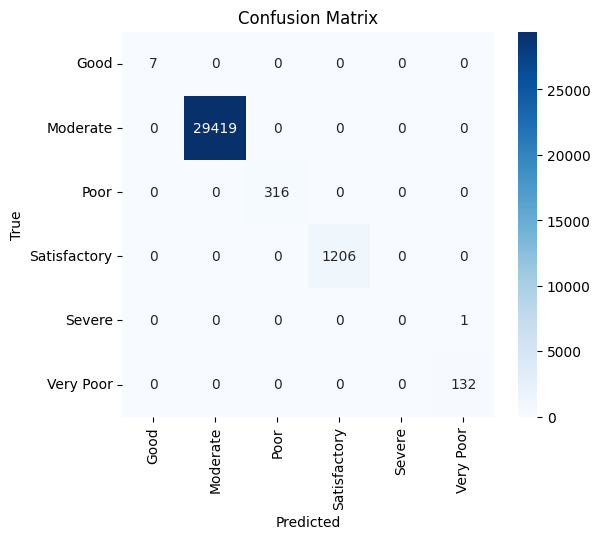

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns # Import seaborn

# Assuming y_test (true labels) and y_pred (predicted labels) are available from previous steps
# Assuming label_enc (LabelEncoder) is available to get class names

# Compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Get the class names
class_names = label_enc.classes_
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=label_enc.classes_, yticklabels=label_enc.classes_, # Corrected variable name from 'le' to 'label_enc'
            cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [8]:
# Count and print the occurrences of each unique location
location_counts = df['Address'].value_counts()
print("=== Location Counts ===")
print(location_counts)
print("\nTotal Unique Locations:", len(location_counts))
print("Total Records with Location Data:", location_counts.sum())

=== Location Counts ===
Address
Kuril Bishow Road, Dhaka, Bangladesh    51810
Uttara, Dhaka, Bangladesh               51800
Tongi, Gazipur, Bangladesh              51795
Name: count, dtype: int64

Total Unique Locations: 3
Total Records with Location Data: 155405


In [10]:
import pandas as pd

# Convert the 'date' column to datetime
df['date_parsed'] = pd.to_datetime(df['date'])

# Get the start and end dates
start_date = df['date_parsed'].min()
end_date = df['date_parsed'].max()

print(f"Start Date & Year: {start_date.strftime('%d-%m-%Y (%I:%M %p)')} (Year: {start_date.year})")
print(f"End Date & Year: {end_date.strftime('%d-%m-%Y (%I:%M %p)')} (Year: {end_date.year})")

Start Date & Year: 01-01-2017 (12:00 AM) (Year: 2017)
End Date & Year: 31-12-2022 (11:00 PM) (Year: 2022)
